# Satellite Data Exploration

## Imports & Setup

In [ ]:
import os
import shutil

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean
import copernicusmarine
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
import xesmf as xe

In [ ]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from utils.paths import (
    SATELLITE_RAW_DIR,
    SATELLITE_PROCESSED_DIR,
    SATELLITE_COVARIATES_ZARR,
    MULTIOBS_ZARR,
    OCCII_CHL_ZARR,
    SATELLITE_FIGURES_DIR,
    ensure_project_dirs,
    print_paths
)

ensure_project_dirs()

SATELLITE_COVARIATES_ZARR_SUBSET = SATELLITE_PROCESSED_DIR / "satellite_covariates_1deg_1970_2024_subset.zarr" # update 

print_paths(
    ("Satellite raw", SATELLITE_RAW_DIR),
    ("Satellite processed", SATELLITE_PROCESSED_DIR),
    ("Satellite covariates", SATELLITE_COVARIATES_ZARR),
    ("Satellite multiobs", MULTIOBS_ZARR),
    ("Satellite occii", OCCII_CHL_ZARR),
    ("Satellite figures", SATELLITE_FIGURES_DIR)
)

### Config

In [ ]:
EXTEND_TO_SOCAT = True
SOCAT_EXT_START = "1970-01-01"
SOCAT_EXT_END = "2024-12-01"
SOCAT_EXT_FREQ = "MS" # month start

# Dataset IDs
MULTIOBS_ID = "cmems_obs-mob_glo_phy_my_0.125deg_P1M-m" # https://data.marine.copernicus.eu/product/MULTIOBS_GLO_PHY_TSUV_3D_MYNRT_015_012/services
GLOBCOL_ID    = "cmems_obs-oc_glo_bgc-plankton_my_l4-multi-4km_P1M" # https://data.marine.copernicus.eu/product/OCEANCOLOUR_GLO_BGC_L4_MY_009_104/services 

# Variable names in MULTIOBS ARMOR3D
# SST=to, SSS=so, MLD=mlotst
MULTIOBS_VARS = ["to", "so", "mlotst"]

# Variable name in GlobColour
GLOBCOL_VARS = ["CHL"]

# Each product downloaded over its own full native coverage
MULTIOBS_START, MULTIOBS_END = "1993-01-01", "2024-12-01"
GLOBCOL_START,    GLOBCOL_END    = "1997-09-01", "2024-12-01"

# Target grid (match ESMs)
TARGET_LAT = np.arange(-89.5, 90, 1.0)   # unchanged, 180 points
TARGET_LON = np.arange(-179.5, 180, 1.0)    # -179.5..179.5, not 0.5..359.5

ds_out = xr.Dataset({
    "lat": (["lat"], TARGET_LAT),
    "lon": (["lon"], TARGET_LON),
})

# Download flags - only download full data on HPC
DOWNLOAD_FULL = IS_HPC

# local test subset: full lat/lon, 2 months, separate windows per product
# (so each product's local test reflects its real start date)
SUBSET_COMMON = {
    "minimum_longitude": -179.5, "maximum_longitude": 179.5,
    "minimum_latitude": -89.5,  "maximum_latitude": 89.5,
}
SUBSET_MULTIOBS = dict(**SUBSET_COMMON, start_datetime="2003-01-01", end_datetime="2003-03-01") # March exclusive
SUBSET_GLOBCOL    = dict(**SUBSET_COMMON, start_datetime="2003-01-01", end_datetime="2003-03-01")

print(f"Full download?: {DOWNLOAD_FULL}")
print(f"MULTIOBS coverage: {MULTIOBS_START} to {MULTIOBS_END}")
print(f"GlobColour coverage:   {GLOBCOL_START} to {GLOBCOL_END}")
print(f"Target grid: {len(TARGET_LAT)}x{len(TARGET_LON)}")

Full download?: True
MULTIOBS coverage: 1993-01-01 to 2024-12-01
GlobColour coverage:   1997-09-01 to 2024-12-01
Reconstruction period (overlap): 1997-09-01 to 2024-12-01
Target grid: 180x360


## Inspect variables (units, resolution, time coverage)

### MULTIOBS ARMOR3D (SST, SSS, MLD)

In [4]:
# Opens lazy remote connection no data downloaded
# https://help.marine.copernicus.eu/en/articles/8287609-copernicus-marine-toolbox-api-open-a-dataset-or-read-a-dataframe-remotely

print("MULTIOBS ARMOR3D inspection:")
ds_multi_inspect = copernicusmarine.open_dataset(
    dataset_id=MULTIOBS_ID,
    minimum_longitude=0,
    maximum_longitude=1,
    minimum_latitude=0,
    maximum_latitude=1,
)
print(ds_multi_inspect)
print(f"\nTime:       {ds_multi_inspect.time.values[0]} to {ds_multi_inspect.time.values[-1]}")
print(f"Resolution: {float(ds_multi_inspect.latitude.diff('latitude').mean()):.4f}°")
print("\nVariable units:")
for var in MULTIOBS_VARS:
    if var in ds_multi_inspect:
        print(f"  {var}: units={ds_multi_inspect[var].attrs.get('units','?')}, "
              f"dims={ds_multi_inspect[var].dims}")
print(f"\nDepth levels: {ds_multi_inspect.depth.values[:5]}...")

MULTIOBS ARMOR3D inspection:


INFO - 2026-08-26T00:38:33Z - Selected dataset version: "202511"


INFO - 2026-08-26T00:38:33Z - Selected dataset part: "default"


<xarray.Dataset> Size: 49MB
Dimensions:    (depth: 50, latitude: 8, longitude: 8, time: 384)
Coordinates:
  * depth      (depth) int16 100B 0 5 10 15 20 25 ... 3500 4000 4500 5000 5500
  * latitude   (latitude) float32 32B 0.0625 0.1875 0.3125 ... 0.8125 0.9375
  * longitude  (longitude) float32 32B 0.0625 0.1875 0.3125 ... 0.8125 0.9375
  * time       (time) datetime64[ns] 3kB 1993-01-01 1993-02-01 ... 2024-12-01
Data variables:
    mlotst     (time, latitude, longitude) float64 197kB dask.array<chunksize=(304, 8, 8), meta=np.ndarray>
    so         (time, depth, latitude, longitude) float64 10MB dask.array<chunksize=(304, 50, 8, 8), meta=np.ndarray>
    to         (time, depth, latitude, longitude) float64 10MB dask.array<chunksize=(304, 50, 8, 8), meta=np.ndarray>
    ugo        (time, depth, latitude, longitude) float64 10MB dask.array<chunksize=(304, 50, 8, 8), meta=np.ndarray>
    vgo        (time, depth, latitude, longitude) float64 10MB dask.array<chunksize=(304, 50, 8, 8), met

SST, SSS are 3D depth-resolved, need extract surface layer.
MLD is fine

### GlobColour Chl-a

In [5]:
print("GlobColour Chl-a inspection:")
ds_chl_inspect = copernicusmarine.open_dataset(
    dataset_id=GLOBCOL_ID,
    minimum_longitude=0,
    maximum_longitude=1,
    minimum_latitude=0,
    maximum_latitude=1,
)
print(ds_chl_inspect)
print(f"\nTime:       {ds_chl_inspect.time.values[0]} to {ds_chl_inspect.time.values[-1]}")
print(f"Resolution: {float(ds_chl_inspect.latitude.diff('lat').mean()):.5f}°")
print("\nVariable units:")
for var in GLOBCOL_VARS:
    if var in ds_chl_inspect:
        print(f"  {var}: units={ds_chl_inspect[var].attrs.get('units','?')}, "
              f"dims={ds_chl_inspect[var].dims}")

GlobColour Chl-a inspection:


INFO - 2026-08-26T00:38:43Z - Selected dataset version: "202603"


INFO - 2026-08-26T00:38:43Z - Selected dataset part: "default"


<xarray.Dataset> Size: 24MB
Dimensions:              (time: 347, latitude: 24, longitude: 24)
Coordinates:
  * time                 (time) datetime64[ns] 3kB 1997-09-01 ... 2026-07-01
  * latitude             (latitude) float32 96B 0.02083 0.0625 ... 0.9375 0.9792
  * longitude            (longitude) float32 96B 0.02084 0.06251 ... 0.9792
Data variables: (12/21)
    CHL                  (time, latitude, longitude) float32 799kB dask.array<chunksize=(347, 24, 24), meta=np.ndarray>
    CHL_uncertainty      (time, latitude, longitude) float64 2MB dask.array<chunksize=(347, 24, 24), meta=np.ndarray>
    DIATO                (time, latitude, longitude) float32 799kB dask.array<chunksize=(347, 24, 24), meta=np.ndarray>
    DIATO_uncertainty    (time, latitude, longitude) float64 2MB dask.array<chunksize=(347, 24, 24), meta=np.ndarray>
    DINO                 (time, latitude, longitude) float32 799kB dask.array<chunksize=(347, 24, 24), meta=np.ndarray>
    DINO_uncertainty     (time, latitud

## Download data

In [ ]:
def _maybe_open_zarr(path):
    if os.path.exists(path):
        print(f"  Loading existing: {path}")
        return xr.open_zarr(path)
    return None

def download_multiobs(save_dir, subset_kwargs=None, save=True, force_download=False):
    """
    Download MULTIOBS ARMOR3D (SST, SSS, MLD). Try loading from caches zarr first if it exists.
    
    If subset_kwargs is None => downloads full global Sep 1997 - Dec 2024 (HPC only)
    If subset_kwargs provided => downloads small subset for local
    
    Extracts surface layer for SST (to) and SSS (so) which are 3D depth-resolved
    MLD (mlotst) is already 2D surface
    
    """
    is_full = subset_kwargs is None

    fname = "multiobs_global.zarr" if is_full else "multiobs_subset.zarr"
    out_path = os.path.join(save_dir, fname)

    if not force_download:
        ds_cached = _maybe_open_zarr(out_path)
        if ds_cached is not None:
            return ds_cached
        
    print(f"Downloading MULTIOBS {'(full global Sep 1997 - Dec 2024)' if is_full else '(subset)'}...")

    open_kwargs = {
        "dataset_id": MULTIOBS_ID,
        "variables": MULTIOBS_VARS,
    }
    if is_full:
        # full global reconstruction period
        open_kwargs.update({
            "start_datetime": MULTIOBS_START,
            "end_datetime": MULTIOBS_END,
        })
    else:
        open_kwargs.update(subset_kwargs)

    ds = copernicusmarine.open_dataset(**open_kwargs)
    print(f"  Raw dims: {dict(ds.dims)}")

    # extract surface layer for 3D vars SST, SSS
    ds_surface = xr.Dataset()
    for var in ["to", "so"]:
        ds_surface[var] = ds[var].isel(depth=0, drop=True) # select shallow level, drop depth coords
    ds_surface["mlotst"] = ds["mlotst"] # already 2D

    # copy time coordinate
    ds_surface = ds_surface.assign_coords(time=ds.time)
    print(f"  Surface dims: {dict(ds_surface.dims)}")
    print(f"  Time: {ds_surface.time.values[0]} to {ds_surface.time.values[-1]}")

    # set units attributes explicitly after surface extraction
    ds_surface["to"].attrs["units"]     = "degrees_C"
    ds_surface["so"].attrs["units"]     = "PSU" 
    ds_surface["mlotst"].attrs["units"] = "m"
    ds_surface["to"].attrs["long_name"]     = "Sea Surface Temperature"
    ds_surface["so"].attrs["long_name"]     = "Sea Surface Salinity"
    ds_surface["mlotst"].attrs["long_name"] = "Mixed Layer Depth"

    if save:
        print(f"  Saving to {out_path}")
        ds_surface.chunk({"time": 12}).to_zarr(out_path, mode="w", zarr_format=2)
        print("  Done.")

    return ds_surface


def download_globcol(save_dir, subset_kwargs=None, save=True, force_download=False):
    """
    Download GlobColour Chl-a. Try loading from caches zarr first if it exists.
    
    If subset_kwargs is None => downloads full global Sep 1997 - Dec 2024 (HPC only)
    If subset_kwargs provided => downloads small subset for local testing
    
    Native resolution: 4km => regrid to 1°x1° in preprocessing
    """
    is_full = subset_kwargs is None

    fname = "globcol_chl_global.zarr" if is_full else "globcol_chl_subset.zarr"
    out_path = os.path.join(save_dir, fname)

    if not force_download:
        ds_cached = _maybe_open_zarr(out_path)
        if ds_cached is not None:
            return ds_cached
    
    print(f"Downloading GlobColour Chl-a {'(full global Sep 1997 - Dec 2024)' if is_full else '(subset)'}...")

    open_kwargs = {
        "dataset_id": GLOBCOL_ID,
        "variables": GLOBCOL_VARS,
    }

    if is_full:
        open_kwargs.update({
            "start_datetime": GLOBCOL_START,
            "end_datetime": GLOBCOL_END,
        })
    else:
        open_kwargs.update(subset_kwargs)

    ds = copernicusmarine.open_dataset(**open_kwargs)
    print(f"  Raw dims: {dict(ds.dims)}")
    print(f"  Time: {ds.time.values[0]} to {ds.time.values[-1]}")

    if save:
        print(f"  Saving to {out_path}...")
        # ds.to_zarr(out_path)
        ds.chunk({"time": 12}).to_zarr(out_path, mode="w", zarr_format=2)
        print("  Done.")

    return ds


## Preprocessing functions

In [7]:
def regrid_to_1deg(ds, ds_out, method="bilinear"):
    """Regrid dataset to 1x1 target grid using xesmf.
    Renames latitude/longitude -> lat/lon to match CMIP6 convention
    """
    # rename coords to match xesmf expectation
    rename_map = {}
    if "latitude"  in ds.coords: rename_map["latitude"]  = "lat"
    if "longitude" in ds.coords: rename_map["longitude"] = "lon"

    if rename_map:
        ds = ds.rename(rename_map)
    
    regridder = xe.Regridder(ds, ds_out, method, periodic=True)
    ds_regridded = regridder(ds)
    print(f"  Regridded: {dict(ds_regridded.dims)}")

    return ds_regridded

In [8]:
SAT_VAR_RENAME = {
    "to": "tos",
    "so": "sos",
    "mlotst": "mlotst",   # already consistent, just kept for completeness
    "CHL": "chlos",
}

def standardise_sat_names(ds):
    """Rename raw Copernicus variable names to CMIP6-style names at the source."""
    rename_map = {k: v for k, v in SAT_VAR_RENAME.items() if k in ds.data_vars}
    return ds.rename(rename_map)

In [9]:
def fill_spatial_nans_with_monthly_climatology(ds, var="chlos", min_climatology_samples=5):
    """
    Fill spatial NaNs in monthly gridded variables using the corresponding
    calendar-month climatology at each grid cell.

    Only NaNs in the original field are replaced. Existing finite values
    are never changed.

    Parameters
    ----------
    ds : xarray.Dataset
        Dataset with dimensions time, lat, lon.
    variables : tuple/list of str
        Variables to fill.
    min_climatology_samples : int
        Minimum number of finite samples required to calculate a climatology
        at a grid cell for a given calendar month.

    Returns
    -------
    xarray.Dataset
        Dataset containing:
        - filled variables with the original names;
        - <variable>_nan_before_fill;
        - <variable>_filled_mask;
        - <variable>_climatology;
        - <variable>_fill_difference.
    """
    ds = ds.copy()

    da = ds[var].transpose("time", "lat", "lon")
    original_nan = da.isnull()

    # Calendar month clim calculated from observations only 
    climatology = (
        da.groupby("time.month")
        .mean("time", skipna=True)
    )

    sample_count = (
        da.notnull()
        .groupby("time.month")
        .sum("time")
    )

    climatology = climatology.where(sample_count >= min_climatology_samples)

    # Select corresponding clim  to each time step
    climatology_at_time = climatology.sel(month=da.time.dt.month)

    fill_mask = original_nan & climatology_at_time.notnull()
    
    # if og value is finite, retain
    # if nan and clim value exists, replace
    # if both og and clim are NaN, retain Nan
    filled = da.where(~fill_mask, climatology_at_time)

    ds[var] = filled.astype(da.dtype)
    ds[f"{var}_nan_before_fill"] = original_nan.astype("int8")
    ds[f"{var}_filled_mask"] = fill_mask.astype("int8")
    ds[f"{var}_filled_value"] = filled.where(fill_mask).astype("float32")
    ds[f"{var}_climatology"] = climatology_at_time.astype("float32")

    print(f"{var} NaNs before fill: {int(original_nan.sum())}")
    print(f"{var} cells filled: {int(fill_mask.sum())}")
    print(f"{var} NaNs after fill: {int(filled.isnull().sum())}")

    return ds

In [10]:
def compute_monthly_anomalies(ds, variables):
    """
    Add monhtly anomaly versions of specified variables.

    For each var, compute a 12-month climatology by averaging all Jan, Feb, ..., Dec values 
    across the available record, then substract that monthly climatology from each timestep.

    Same approach as CMIP6 notebooks, both raw and anomaly vars kept in dataset.
    """
    ds = ds.copy()

    for var in variables:
        if var in ds:
            clim = ds[var].groupby("time.month").mean(dim="time")
            ds[f"{var}_anom"] = ds[var].groupby("time.month") - clim
            ds[f"{var}_anom"].attrs = {
                "long_name": f"{var} monthly anomaly",
                "units": ds[var].attrs.get("units", ""),
            }
            print(f"  Computed anomaly: {var}_anom")
            
    return ds

In [11]:
def extend_with_monthly_climatology(ds, target_times, variables):
    """
    Extend selected monthly variables to a new target timeline (SOCAT gridded monthly 1970-2024)

    For each requested month:
    - use real observed/regridded value if that exact year-month exists in ds
    - otherwise use long-term monthly climatology for that calendar month.

    Only used for months before dataset coverage begins 
    (i.e. before 1993-01 for MULTIOBS, before 1997-09 for GlobColour CHL).

    Parameters
    ----------
    ds: xr.Dataset
        Regridded monthly dataset with a 'time' coordinate and variables on
        (time, lat, lon).
    target_times: array-like
        Monthly timestamps to extend onto, e.g. pd.date_range("1970-01-01", ...).
    variables: list[str]
        Variable names to extend ["to", "so", "mlotst"] or ["CHL"].

    Returns
    -------
    xr.Dataset
        Dataset on target_times containing extended raw vars and their monthly anomalies
    """
    target_times = pd.to_datetime(target_times)
    ds_out_ext = xr.Dataset(coords={"time": target_times, "lat": ds["lat"], "lon": ds["lon"]})

    # Build quick lookup of available real months in the source dataset.
    available_times = pd.to_datetime(ds.time.values)
    real_month_lookup = {(t.year, t.month): t for t in available_times}

    for var in variables:
        da = ds[var]

        # Monthly climatology used only when requested month is outside real record coverage
        clim = da.groupby("time.month").mean(dim="time")

        extended_arrays = []
        for t in target_times:
            key = (t.year, t.month)

            if key in real_month_lookup:
                # Use real month whenever exists in ds
                arr = da.sel(time=real_month_lookup[key]).values
            else:
                # Otherwise fill with climatological mean for that month
                arr = clim.sel(month=t.month).values

            extended_arrays.append(arr)

        extended_stack = np.stack(extended_arrays, axis=0) # (time, lat. lon)

        ds_out_ext[var] = xr.DataArray(
            extended_stack,
            dims=["time", "lat", "lon"],
            coords={"time": target_times, "lat": ds["lat"], "lon": ds["lon"]},
            attrs=da.attrs,
        )

    # Add anomaly fields after extension (= consistent on final target timeline)
    ds_out_ext = compute_monthly_anomalies(ds_out_ext, variables)

    return ds_out_ext

### Full HPC processing run

In [12]:
def open_if_exists(path):
    if os.path.exists(path):
        print(f"  Found existing processed file: {path}")
        return xr.open_zarr(path)
    return None

In [ ]:
if IS_HPC:
    print("Running full HPC satellite pipeline...")

    ds_multi = download_multiobs(SATELLITE_RAW_DIR, subset_kwargs=None, save=True)
    ds_chl = download_globcol(SATELLITE_RAW_DIR, subset_kwargs=None, save=True)

    ds_multi_cached = open_if_exists(MULTIOBS_ZARR)
    if ds_multi_cached is None:
        print("\nPreprocessing MULTIOBS...")
        ds_multi_regrid = regrid_to_1deg(ds_multi, ds_out)
        ds_multi_regrid = standardise_sat_names(ds_multi_regrid)
        ds_multi_regrid = fill_spatial_nans_with_monthly_climatology(ds_multi_regrid, var="mlotst")
        ds_multi_regrid = compute_monthly_anomalies(ds_multi_regrid, ["tos", "sos", "mlotst"])
        ds_multi_regrid.chunk({"time": 12, "lat": 180, "lon": 360}).to_zarr(MULTIOBS_ZARR, mode="w", zarr_format=2)
        print(f"  Saved MULTIOBS to {MULTIOBS_ZARR}")
    else:
        ds_multi_regrid = ds_multi_cached

    ds_chl_cached = open_if_exists(OCCII_CHL_ZARR)
    if ds_chl_cached is None:
        print("\nPreprocessing GlobColour Chl-a...")
        ds_chl_regrid = regrid_to_1deg(ds_chl, ds_out)
        ds_chl_regrid = standardise_sat_names(ds_chl_regrid)
        ds_chl_regrid = fill_spatial_nans_with_monthly_climatology(ds_chl_regrid, var="chlos")
        ds_chl_regrid = compute_monthly_anomalies(ds_chl_regrid, ["chlos"])
        ds_chl_regrid.chunk({"time": 12, "lat": 180, "lon": 360}).to_zarr(OCCII_CHL_ZARR, mode="w", zarr_format=2)
        print(f"  Saved GlobColour to {OCCII_CHL_ZARR}")
    else:
        ds_chl_regrid = ds_chl_cached

    if EXTEND_TO_SOCAT:
        ds_ext_cached = open_if_exists(SATELLITE_COVARIATES_ZARR)
        if ds_ext_cached is None:
            print("\nExtending satellite covariates to SOCAT monthly timeline...")
            socat_times = pd.date_range(SOCAT_EXT_START, SOCAT_EXT_END, freq=SOCAT_EXT_FREQ) # 1970- range
            ds_multi_ext = extend_with_monthly_climatology(ds_multi_regrid, target_times=socat_times, variables=["tos", "sos", "mlotst"])
            ds_chl_ext = extend_with_monthly_climatology(ds_chl_regrid, target_times=socat_times, variables=["chlos"])
            # ds_satellite_ext = xr.merge([ds_multi_ext, ds_chl_ext])  # future warning
            
            ds_satellite_ext = xr.merge(
                            [ds_multi_ext, ds_chl_ext],
                            compat="override",      # when coords overlap and match, take the 1st without conflict checking
                            join="exact",           # fail loudly if lat/lon/time dont align exactly instead of silently reindexing
                            combine_attrs="override"
            ) 
            print("Merged dataset:")
            print(ds_satellite_ext)
            print("Merge produced any NaN-only variables:", {v: bool(ds_satellite_ext[v].isnull().all()) for v in ds_satellite_ext.data_vars})
            
            ds_satellite_ext.chunk({"time": 12, "lat": 180, "lon": 360}).to_zarr(SATELLITE_COVARIATES_ZARR, mode="w", zarr_format=2)

            print(f"  Saved extended satellite covariates to {SATELLITE_COVARIATES_ZARR}")
            print("  Extended coverage:", str(ds_satellite_ext.time.values[0])[:10], "tos", str(ds_satellite_ext.time.values[-1])[:10])
        else:
            ds_satellite_ext = ds_ext_cached
            print(f"  Using existing extended satellite covariates: {SATELLITE_COVARIATES_ZARR}")
            print("  Extended coverage:", str(ds_satellite_ext.time.values[0])[:10], "tos", str(ds_satellite_ext.time.values[-1])[:10])

    print(f"\nDone. MULTIOBS vars: {list(ds_multi_regrid.data_vars)}")
    print(f"      GlobColour vars:   {list(ds_chl_regrid.data_vars)}")
else: # local
    print("Local mode: downloading 2-month global subset for testing...")
    ds_multi = download_multiobs(SATELLITE_RAW_DIR, subset_kwargs=SUBSET_MULTIOBS, save=True)
    ds_chl = download_globcol(SATELLITE_RAW_DIR, subset_kwargs=SUBSET_GLOBCOL, save=True)

    ds_multi_cached = open_if_exists(MULTIOBS_ZARR)
    if ds_multi_cached is None:
        print("\nPreprocessing MULTIOBS subset...")
        ds_multi_regrid = regrid_to_1deg(ds_multi, ds_out)
        ds_multi_regrid = standardise_sat_names(ds_multi_regrid)
        ds_multi_regrid = fill_spatial_nans_with_monthly_climatology(ds_multi_regrid, var="mlotst")
        ds_multi_regrid = compute_monthly_anomalies(ds_multi_regrid, ["tos", "sos", "mlotst"])
    else:
        ds_multi_regrid = ds_multi_cached
        print(f"  Using existing processed MULTIOBS: {MULTIOBS_ZARR}")

    ds_chl_cached = open_if_exists(OCCII_CHL_ZARR)
    if ds_chl_cached is None:
        print("\nPreprocessing GlobColour subset...")
        ds_chl_regrid = regrid_to_1deg(ds_chl, ds_out)
        ds_chl_regrid = standardise_sat_names(ds_chl_regrid)
        ds_chl_regrid = fill_spatial_nans_with_monthly_climatology(ds_chl_regrid, var="chlos")
        ds_chl_regrid = compute_monthly_anomalies(ds_chl_regrid, ["chlos"])
    else:
        ds_chl_regrid = ds_chl_cached
        print(f"  Using existing processed GlobColour: {OCCII_CHL_ZARR}")

    if EXTEND_TO_SOCAT:
        ds_ext_cached = open_if_exists(SATELLITE_COVARIATES_ZARR_SUBSET)
        if ds_ext_cached is None:
            print("\nExtending subset products to SOCAT monthly timeline...")

            socat_times = pd.date_range(SOCAT_EXT_START, SOCAT_EXT_END, freq=SOCAT_EXT_FREQ)
            ds_multi_ext = extend_with_monthly_climatology(ds_multi_regrid, target_times=socat_times, variables=["tos", "sos", "mlotst"])
            ds_chl_ext = extend_with_monthly_climatology(ds_chl_regrid, target_times=socat_times, variables=["chlos"])
            
            ds_satellite_ext = xr.merge(
                [ds_multi_ext, ds_chl_ext],
                compat="override",      # when coords overlap and match, take the 1st without conflict checking
                join="exact",           # fail loudly if lat/lon/time dont align exactly instead of silently reindexing
                combine_attrs="override"
            ) 
            print("Merged dataset:")
            print(ds_satellite_ext)
            print("Merge produced any NaN-only variables:", {v: bool(ds_satellite_ext[v].isnull().all()) for v in ds_satellite_ext.data_vars})
            
            ds_satellite_ext.chunk({"time": 12, "lat": 180, "lon": 360}).to_zarr(SATELLITE_COVARIATES_ZARR_SUBSET, mode="w", zarr_format=2)

            print(f"  Saved extended subset satellite covariates to {SATELLITE_COVARIATES_ZARR_SUBSET}")
            print("  Extended coverage:", str(ds_satellite_ext.time.values[0])[:10], "tos", str(ds_satellite_ext.time.values[-1])[:10])
        else:
            ds_satellite_ext = ds_ext_cached
            print(f"  Using existing extended subset satellite covariates: {SATELLITE_COVARIATES_ZARR_SUBSET}")
            print("  Extended coverage:", str(ds_satellite_ext.time.values[0])[:10], "tos", str(ds_satellite_ext.time.values[-1])[:10])
            
        assert float(ds_satellite_ext.lon.min()) >= 0, "Satellite lon not in 0-360 convention"
        assert float(ds_satellite_ext.lon.max()) <= 360, "Satellite lon not in 0-360 convention"
        print("Satellite lon range:", float(ds_satellite_ext.lon.min()), "to", float(ds_satellite_ext.lon.max()))

    print(f"\nDone. MULTIOBS vars: {list(ds_multi_regrid.data_vars)}")
    print(f"      GlobColour vars:   {list(ds_chl_regrid.data_vars)}")

Running full HPC satellite pipeline...
  Loading existing: /rds/general/user/efs25/home/irp-efs25/data/raw/satellite/multiobs_global.zarr
  Loading existing: /rds/general/user/efs25/home/irp-efs25/data/raw/satellite/globcol_chl_global.zarr

Preprocessing MULTIOBS...


/var/tmp/pbs.3915211.pbs-7/ipykernel_2892036/4129584372.py:15: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  print(f"  Regridded: {dict(ds_regridded.dims)}")


  Regridded: {'time': 384, 'lat': 180, 'lon': 360}


mlotst NaNs before fill: 9227091


mlotst cells filled: 408561


...

  Computed anomaly: tos_anom


  Computed anomaly: sos_anom


  Computed anomaly: mlotst_anom


  Computed anomaly: chlos_anom
Merged dataset:
<xarray.Dataset> Size: 2GB
Dimensions:      (lat: 180, lon: 360, time: 660)
Coordinates:
  * lat          (lat) float64 1kB -89.5 -88.5 -87.5 -86.5 ... 87.5 88.5 89.5
  * lon          (lon) float64 3kB -179.5 -178.5 -177.5 ... 177.5 178.5 179.5
  * time         (time) datetime64[ns] 5kB 1970-01-01 1970-02-01 ... 2024-12-01
    month        (time) int64 5kB 1 2 3 4 5 6 7 8 9 10 ... 4 5 6 7 8 9 10 11 12
Data variables:
    tos          (time, lat, lon) float64 342MB nan nan nan ... -1.611 -1.611
    sos          (time, lat, lon) float64 342MB nan nan nan ... 29.52 29.52
    mlotst       (time, lat, lon) float64 342MB nan nan nan ... 20.35 20.55
    tos_anom     (time, lat, lon) float64 342MB nan nan ... -0.0005625
    sos_anom     (time, lat, lon) float64 342MB nan nan ... -0.0005937
    mlotst_anom  (time, lat, lon) float64 342MB nan nan nan ... -0.5875 -0.8875
    chlos        (time, lat, lon) float32 171MB nan nan nan nan ... nan nan nan


  Saved extended satellite covariates to /rds/general/user/efs25/home/irp-efs25/data/processed/satellite/satellite_covariates_1deg_1970_2024.zarr
  Extended coverage: 1970-01-01 tos 2024-12-01

Done. MULTIOBS vars: ['mlotst', 'sos', 'tos', 'mlotst_nan_before_fill', 'mlotst_filled_mask', 'mlotst_filled_value', 'mlotst_climatology', 'tos_anom', 'sos_anom', 'mlotst_anom']
      GlobColour vars:   ['chlos', 'chlos_anom', 'chlos_climatology', 'chlos_filled_mask', 'chlos_filled_value', 'chlos_nan_before_fill']


#### diagnostics

In [14]:
# verify real_month_lookup keys and climatology fallback logic
def debug_real_month_lookup(ds, target_times):
    target_times = pd.to_datetime(target_times)
    available_times = pd.to_datetime(ds.time.values)
    real_month_lookup = {(t.year, t.month): t for t in available_times}

    print("Number of real months available:", len(real_month_lookup))
    print("Sample keys:", list(real_month_lookup.items())[:3])

    # Check for duplicate (year, month) keys ow would silently overwrite
    keys = [(t.year, t.month) for t in available_times]
    dupes = len(keys) - len(set(keys))
    print("Duplicate (year, month) collisions in source data:", dupes)

    # Check which target months fall back to climatology vs real data
    fallback_count = 0
    real_count = 0
    fallback_months = []
    for t in target_times:
        key = (t.year, t.month)
        if key in real_month_lookup:
            real_count += 1
        else:
            fallback_count += 1
            fallback_months.append(t)

    print(f"Target months using REAL data: {real_count}")
    print(f"Target months using CLIMATOLOGY fallback: {fallback_count}")
    print("First 5 fallback months:", fallback_months[:5])
    print("Last 5 fallback months:", fallback_months[-5:])

    # fallback should ONLY be pre-coverage months, not scattered gaps
    coverage_start = available_times.min()
    unexpected_fallback = [t for t in fallback_months if t >= coverage_start]
    print("Unexpected fallback months WITHIN real coverage window:", len(unexpected_fallback))
    if unexpected_fallback:
        print("  -> These indicate real gaps/missing months inside coverage:", unexpected_fallback[:10])

    return real_month_lookup

socat_times = pd.date_range(SOCAT_EXT_START, SOCAT_EXT_END, freq=SOCAT_EXT_FREQ)
_ = debug_real_month_lookup(ds_multi_regrid, socat_times)
_ = debug_real_month_lookup(ds_chl_regrid, socat_times)

Number of real months available: 384
Sample keys: [((1993, 1), Timestamp('1993-01-01 00:00:00')), ((1993, 2), Timestamp('1993-02-01 00:00:00')), ((1993, 3), Timestamp('1993-03-01 00:00:00'))]
Duplicate (year, month) collisions in source data: 0
Target months using REAL data: 384
Target months using CLIMATOLOGY fallback: 276
First 5 fallback months: [Timestamp('1970-01-01 00:00:00'), Timestamp('1970-02-01 00:00:00'), Timestamp('1970-03-01 00:00:00'), Timestamp('1970-04-01 00:00:00'), Timestamp('1970-05-01 00:00:00')]
Last 5 fallback months: [Timestamp('1992-08-01 00:00:00'), Timestamp('1992-09-01 00:00:00'), Timestamp('1992-10-01 00:00:00'), Timestamp('1992-11-01 00:00:00'), Timestamp('1992-12-01 00:00:00')]
Unexpected fallback months WITHIN real coverage window: 0
Number of real months available: 328
Sample keys: [((1997, 9), Timestamp('1997-09-01 00:00:00')), ((1997, 10), Timestamp('1997-10-01 00:00:00')), ((1997, 11), Timestamp('1997-11-01 00:00:00'))]
Duplicate (year, month) collisi

Chlorophyll diagnostics

March 2003 original NaNs: 29957
March 2003 filled cells: 1688
March 2003 remaining NaNs: 28269


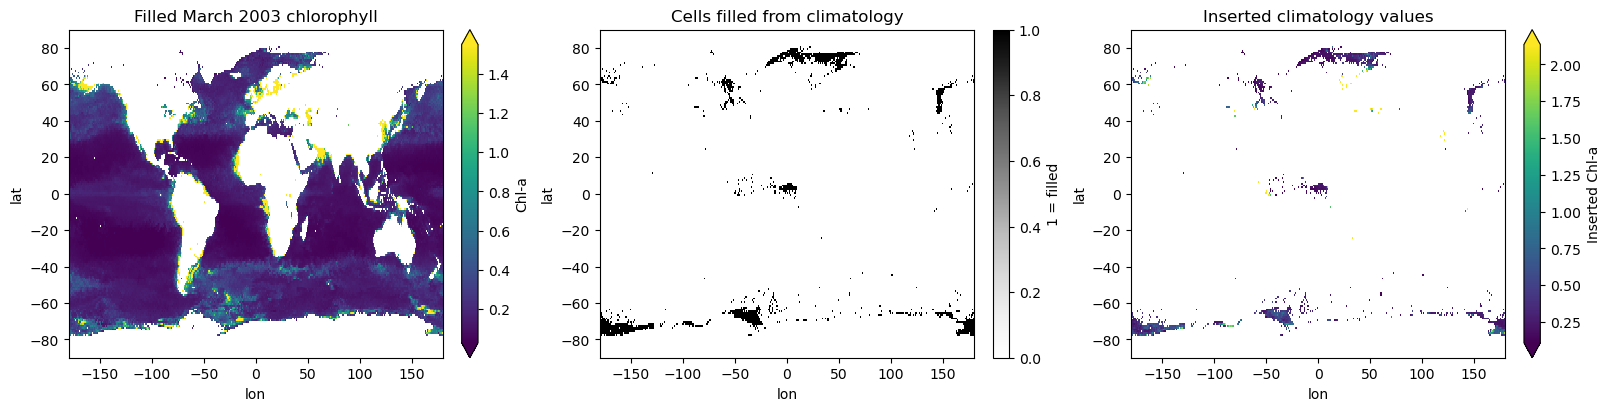

In [15]:
# march 2003 fill
march = ds_chl_regrid.sel(
    time="2003-03-01",
    method="nearest",
)

print("March 2003 original NaNs:", int(march["chlos_nan_before_fill"].sum()))
print("March 2003 filled cells:", int(march["chlos_filled_mask"].sum()))
print("March 2003 remaining NaNs:", int(march["chlos"].isnull().sum()))

fig, axes = plt.subplots(1, 3, figsize=(16, 4), constrained_layout=True)

march["chlos"].plot(
    ax=axes[0],
    cmap="viridis",
    robust=True,
    cbar_kwargs={"label": "Chl-a"},
)
axes[0].set_title("Filled March 2003 chlorophyll")

march["chlos_filled_mask"].plot(
    ax=axes[1],
    cmap="Greys",
    vmin=0,
    vmax=1,
    cbar_kwargs={"label": "1 = filled"},
)
axes[1].set_title("Cells filled from climatology")

march["chlos_filled_value"].plot(
    ax=axes[2],
    cmap="viridis",
    robust=True,
    cbar_kwargs={"label": "Inserted Chl-a"},
)
axes[2].set_title("Inserted climatology values")

plt.show()

In [16]:
print("MLD NaNs before fill:", int(ds_multi["mlotst"].isnull().sum()))
print("MLD NaNs after fill:", int(ds_multi_regrid["mlotst"].isnull().sum()))

MLD NaNs before fill: 506353364


MLD NaNs after fill: 8818530


In [17]:
if EXTEND_TO_SOCAT:
    # verify lat/lon coordinates are identical before merging
    def check_merge_compat(ds_a, ds_b, name_a="MULTIOBS", name_b="GlobColour"):
        lat_match = np.allclose(ds_a.lat.values, ds_b.lat.values)
        lon_match = np.allclose(ds_a.lon.values, ds_b.lon.values)
        time_match = np.array_equal(ds_a.time.values, ds_b.time.values)

        print(f"{name_a} lat range: {ds_a.lat.values.min()} to {ds_a.lat.values.max()}, n={ds_a.sizes['lat']}")
        print(f"{name_b} lat range: {ds_b.lat.values.min()} to {ds_b.lat.values.max()}, n={ds_b.sizes['lat']}")
        print("Lat coords identical:", lat_match)
        print("Lon coords identical:", lon_match)
        print("Time coords identical:", time_match)

        if not (lat_match and lon_match and time_match):
            print("WARNING: coordinates differ, merge will need alignment/interpolation")
        return lat_match and lon_match and time_match

    coords_ok = check_merge_compat(ds_multi_ext, ds_chl_ext)

MULTIOBS lat range: -89.5 to 89.5, n=180
GlobColour lat range: -89.5 to 89.5, n=180
Lat coords identical: True
Lon coords identical: True
Time coords identical: True


#### Preprocessing sanity check 

In [18]:
time_label = str(ds_multi_regrid.time.values[0])[:7]
print(f"Time: {time_label} (isel(time=0))\n")

for var, label in [
    ("tos",    "SST (°C)"),
    ("sos",    "SSS (PSU)"),
    ("mlotst", "MLD (m)"),
]:
    vals = ds_multi_regrid[var].isel(time=0).values.flatten()
    valid = vals[~np.isnan(vals)]
    if len(valid) > 0:
        print(f"  {label}: median={np.median(valid):.2f}, min={valid.min():.2f}, max={valid.max():.2f}")
    else:
        print(f"  {label}: no valid values")

chl_vals = ds_chl_regrid["chlos"].isel(time=0).values.flatten()
chl_valid = chl_vals[(~np.isnan(chl_vals)) & (chl_vals > 0)]
print(f"  Chl-a (mg/m³): median={np.median(chl_valid):.4f}, min={chl_valid.min():.4f}, max={chl_valid.max():.2f}")

Time: 1993-01 (isel(time=0))



  SST (°C): median=15.13, min=-1.82, max=30.79


  SSS (PSU): median=34.31, min=5.52, max=40.00


  MLD (m): median=26.65, min=10.30, max=1297.65
  Chl-a (mg/m³): median=0.1526, min=0.0187, max=31.20


## Visualise

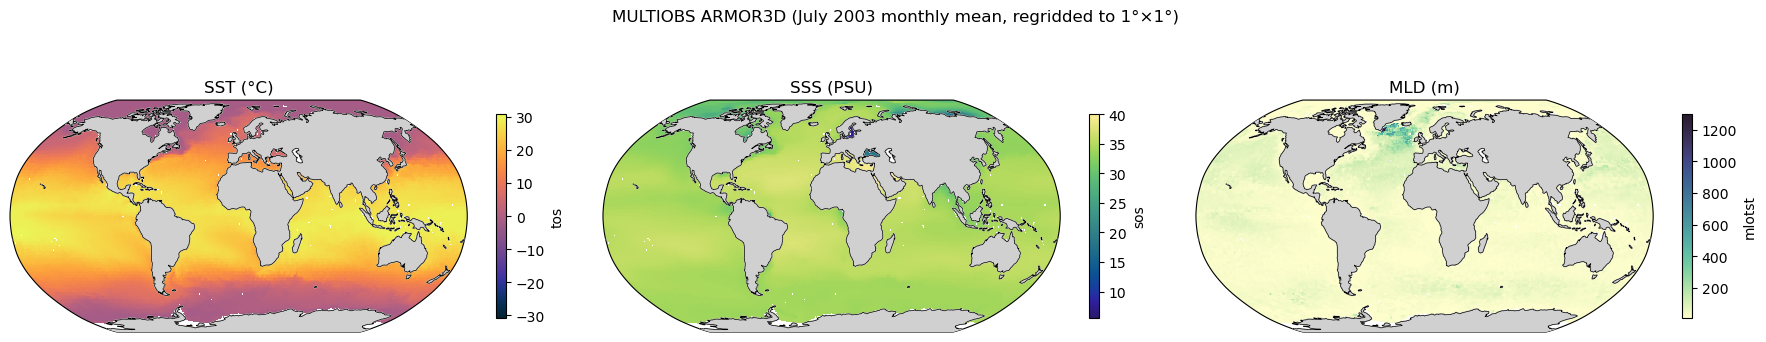

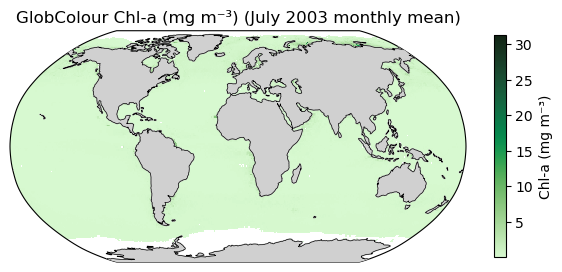

In [ ]:
if IS_HPC:
    t0 = ds_multi_regrid.sel(time="2003-07", method="nearest").time.values
    time_label = pd.Timestamp(t0).strftime("%B %Y")  # "July 2003"

    # MULTIOBS maps
    fig, axes = plt.subplots(1, 3, figsize=(18, 4), subplot_kw={"projection": ccrs.Robinson()})

    plots = [
        (ds_multi_regrid["tos"].isel(time=0),     "SST (°C)",  cmocean.cm.thermal),
        (ds_multi_regrid["sos"].isel(time=0),     "SSS (PSU)", cmocean.cm.haline),
        (ds_multi_regrid["mlotst"].isel(time=0), "MLD (m)",   cmocean.cm.deep),
    ]

    for ax, (data, title, cmap) in zip(axes, plots):
        data.plot(ax=ax, transform=ccrs.PlateCarree(), cmap=cmap, cbar_kwargs={"shrink": 0.6})
        ax.add_feature(cfeature.LAND, color="#d0d0d0", zorder=3)
        ax.add_feature(cfeature.COASTLINE, linewidth=0.5, zorder=4)
        ax.set_title(title)

    plt.suptitle(f"MULTIOBS ARMOR3D ({time_label} monthly mean, regridded to 1°×1°)")
    plt.tight_layout()
    plt.savefig(os.path.join(SATELLITE_FIGURES_DIR, "satellite_multiobs.png"), dpi=150, bbox_inches="tight")
    plt.show()

    # Chl-a map
    fig, ax = plt.subplots(figsize=(6, 4), subplot_kw={"projection": ccrs.Robinson()})
    chl_plot = ds_chl_regrid["chlos"].isel(time=0)
    chl_plot.where(chl_plot > 0).plot(
        ax=ax, transform=ccrs.PlateCarree(),
        cmap=cmocean.cm.algae,
        cbar_kwargs={"label": "Chl-a (mg m⁻³)", "shrink": 0.6}
    )
    ax.add_feature(cfeature.LAND, color="#d0d0d0", zorder=3)
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5, zorder=4)
    ax.set_title(f"GlobColour Chl-a (mg m⁻³) ({time_label} monthly mean)")
    plt.tight_layout()
    plt.savefig(os.path.join(SATELLITE_FIGURES_DIR, "satellite_globcol_chl.png"), dpi=150, bbox_inches="tight")
    plt.show()

## Covariate distribution comparison


CMIP6 CanESM5 loaded for comparison


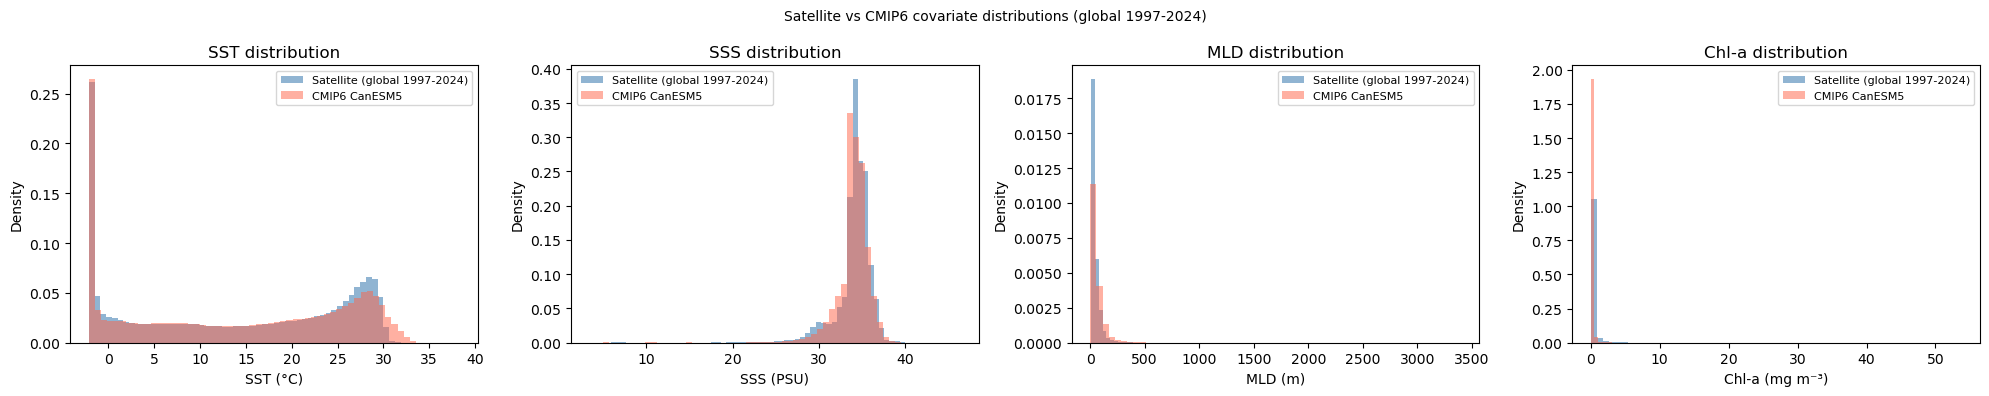

In [ ]:
def get_valid_vals(da):
    """Get valid ocean values, mask NaN and zeros"""
    vals = da.values.flatten()
    return vals[(~np.isnan(vals)) & (vals != 0)]


cmip6_path = os.path.join(DATA_ROOT, "processed", "cmip6", "CanESM5.zarr")
has_cmip = os.path.exists(cmip6_path)
region_note = "global 1997-2024" if IS_HPC else "2-month subset Jan-Feb 2003"


if has_cmip:
    ds_cmip = xr.open_zarr(cmip6_path)
    print("CMIP6 CanESM5 loaded for comparison")
else:
    print(f"CMIP6 data not found at {cmip6_path}, showing satellite only")

VAR_MAP = [
    ("tos",     "tos",    "SST",   "°C"),
    ("sos",     "sos",    "SSS",   "PSU"),
    ("mlotst", "mlotst", "MLD",   "m"),
    ("chlos",    "chlos",  "Chl-a", "mg m⁻³"),
]

fig, axes = plt.subplots(1, 4, figsize=(20, 4))

for ax, (sat_var, cmip_var, label, unit) in zip(axes, VAR_MAP):
    ds_sat = ds_chl_regrid if sat_var == "chlos" else ds_multi_regrid
    sat_vals = get_valid_vals(ds_sat[sat_var])
    ax.hist(sat_vals, bins=60, density=True, alpha=0.6, color="steelblue", label=f"Satellite ({region_note})")

    if has_cmip and cmip_var in ds_cmip:
        cmip_vals = get_valid_vals(ds_cmip[cmip_var])
        ax.hist(cmip_vals, bins=60, density=True, alpha=0.5, color="tomato", label="CMIP6 CanESM5")

    ax.set_xlabel(f"{label} ({unit})")
    ax.set_ylabel("Density")
    ax.set_title(f"{label} distribution")
    ax.legend(fontsize=8)

plt.suptitle(f"Satellite vs CMIP6 covariate distributions ({region_note})", fontsize=10)
plt.tight_layout()
fname = "satellite_vs_cmip6_distributions_global.png" if IS_HPC else "satellite_vs_cmip6_distributions_subset.png"
plt.savefig(os.path.join(SATELLITE_FIGURES_DIR, fname), dpi=150, bbox_inches="tight")
plt.show()